# Colorectal Cancer Risk & Survival Prediction

## Objective
The goal of this project is to predict the **survival status** of colorectal cancer patients based on their demographics, medical history, and lifestyle factors.

## Dataset Overview
The dataset contains records of **colorectal cancer patients**, with features related to risk factors, treatment, and outcomes.

## Instructions
1. **Data Exploration**: Load and examine the dataset.
2. **Data Preprocessing**: Handle missing values, encode categorical variables, and normalize numerical features.
3. **Feature Selection**: Identify important predictors for survival.
4. **Model Training**: Train a classification model to predict survival status.
5. **Evaluation**: Assess model performance using accuracy and classification reports.

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, roc_auc_score, RocCurveDisplay

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

In [2]:
# Load the dataset
df = pd.read_csv('colorectal_cancer_prediction.csv')

# Display basic information about the dataset
print(f'Shape: {df.shape}')
df.info()
df.head()

Shape: (89945, 30)
<class 'pandas.DataFrame'>
RangeIndex: 89945 entries, 0 to 89944
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Patient_ID               89945 non-null  int64  
 1   Age                      89945 non-null  int64  
 2   Gender                   89945 non-null  str    
 3   Race                     89945 non-null  str    
 4   Region                   89945 non-null  str    
 5   Urban_or_Rural           89945 non-null  str    
 6   Socioeconomic_Status     89945 non-null  str    
 7   Family_History           89945 non-null  str    
 8   Previous_Cancer_History  89945 non-null  str    
 9   Stage_at_Diagnosis       89945 non-null  str    
 10  Tumor_Aggressiveness     89945 non-null  str    
 11  Colonoscopy_Access       89945 non-null  str    
 12  Screening_Regularity     89945 non-null  str    
 13  Diet_Type                89945 non-null  str    
 14  BMI           

,Patient_ID,Age,Gender,Race,Region,Urban_or_Rural,Socioeconomic_Status,Family_History,Previous_Cancer_History,Stage_at_Diagnosis,Tumor_Aggressiveness,Colonoscopy_Access,Screening_Regularity,Diet_Type,BMI,Physical_Activity_Level,Smoking_Status,Alcohol_Consumption,Red_Meat_Consumption,Fiber_Consumption,Insurance_Coverage,Time_to_Diagnosis,Treatment_Access,Chemotherapy_Received,Radiotherapy_Received,Surgery_Received,Follow_Up_Adherence,Survival_Status,Recurrence,Time_to_Recurrence
0,1,71,Male,Other,Europe,Urban,Middle,Yes,No,III,High,No,Regular,Western,33.0,Low,Never,Low,Low,Low,Yes,Delayed,Good,Yes,No,No,Good,Survived,No,16
1,2,34,Female,Black,North America,Urban,Middle,No,No,I,Medium,Yes,Regular,Western,33.1,Medium,Never,Low,Low,Low,No,Timely,Good,No,Yes,Yes,Poor,Deceased,No,28
2,3,80,Female,White,North America,Urban,Middle,No,No,III,Low,Yes,Regular,Balanced,20.7,Medium,Never,Low,Low,Medium,Yes,Timely,Limited,No,Yes,Yes,Good,Survived,No,26
3,4,40,Male,Black,North America,Rural,Low,No,No,I,Medium,Yes,Never,Traditional,38.9,Medium,Former,Low,Low,High,Yes,Delayed,Limited,Yes,No,Yes,Poor,Deceased,No,44
4,5,43,Female,White,Europe,Urban,High,Yes,No,III,Low,Yes,Never,Traditional,24.8,Medium,Former,High,Medium,Low,No,Delayed,Good,Yes,No,Yes,Poor,Deceased,Yes,20


## Exploratory Data Analysis (EDA)
- Check for missing values
- Visualize key distributions
- Identify correlations between features

In [3]:
# Check for missing values
missing = df.isnull().sum()
print('Missing values per column:')
print(missing[missing > 0] if missing.sum() > 0 else 'No missing values found.')

Missing values per column:
No missing values found.


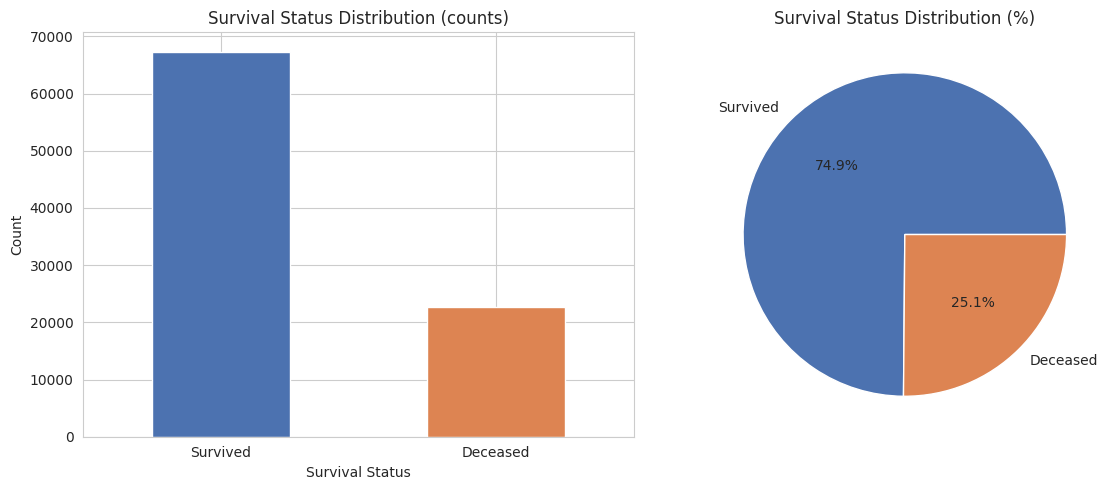

Survival_Status
Survived    67341
Deceased    22604
Name: count, dtype: int64


In [4]:
# Visualize survival status distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df['Survival_Status'].value_counts().plot(kind='bar', ax=axes[0], color=['#4C72B0', '#DD8452'])
axes[0].set_title('Survival Status Distribution (counts)')
axes[0].set_xlabel('Survival Status')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=0)

df['Survival_Status'].value_counts(normalize=True).mul(100).plot(
    kind='pie', ax=axes[1], autopct='%1.1f%%', colors=['#4C72B0', '#DD8452'])
axes[1].set_ylabel('')
axes[1].set_title('Survival Status Distribution (%)')

plt.tight_layout()
plt.show()

print(df['Survival_Status'].value_counts())

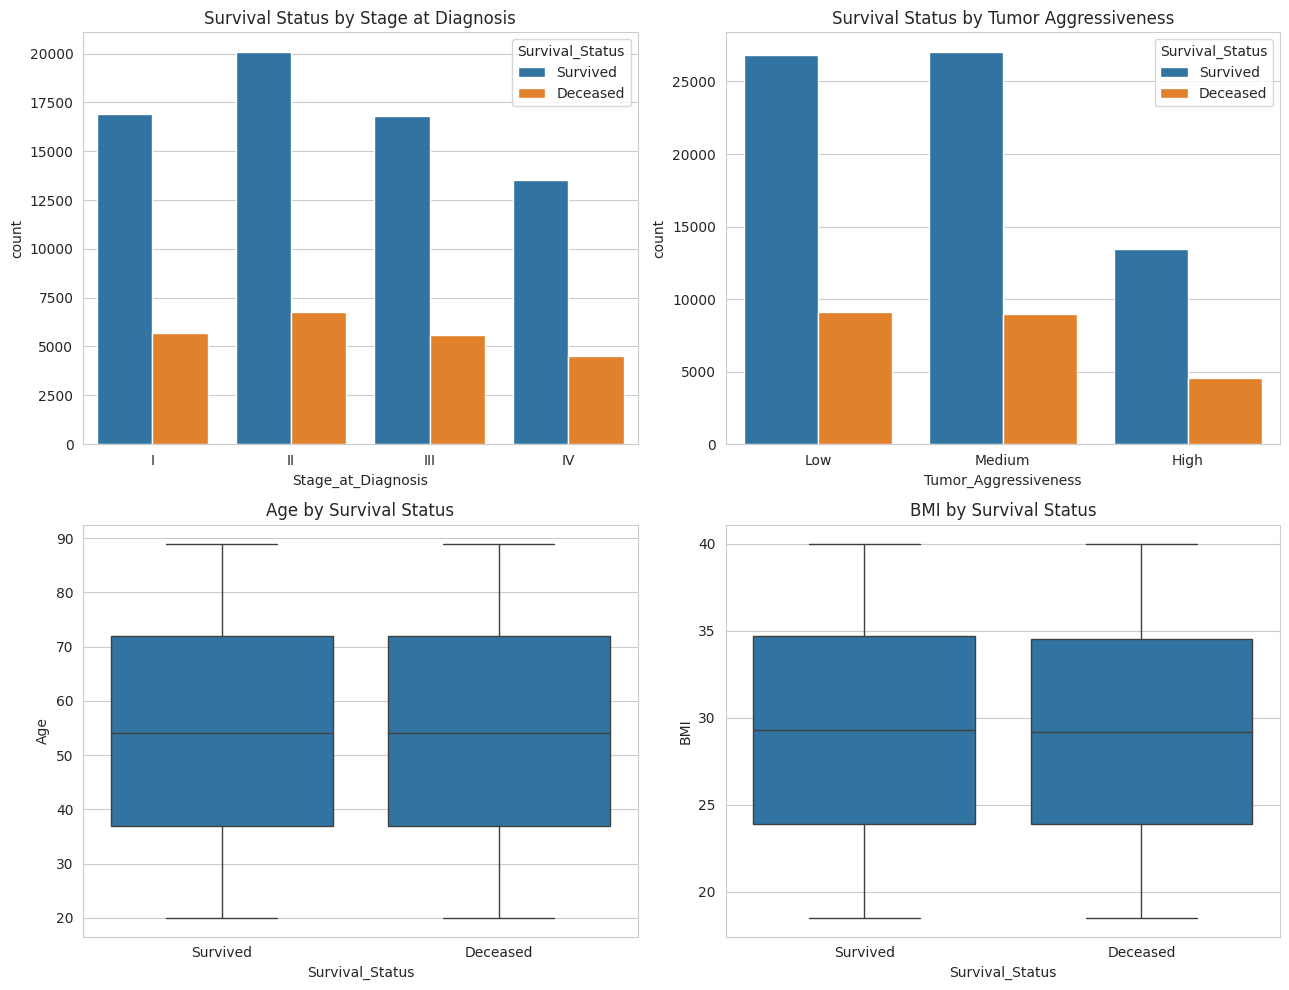

In [5]:
# Survival status by key clinical factors
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

sns.countplot(data=df, x='Stage_at_Diagnosis', hue='Survival_Status',
              order=['I', 'II', 'III', 'IV'], ax=axes[0, 0])
axes[0, 0].set_title('Survival Status by Stage at Diagnosis')

sns.countplot(data=df, x='Tumor_Aggressiveness', hue='Survival_Status',
              order=['Low', 'Medium', 'High'], ax=axes[0, 1])
axes[0, 1].set_title('Survival Status by Tumor Aggressiveness')

sns.boxplot(data=df, x='Survival_Status', y='Age', ax=axes[1, 0])
axes[1, 0].set_title('Age by Survival Status')

sns.boxplot(data=df, x='Survival_Status', y='BMI', ax=axes[1, 1])
axes[1, 1].set_title('BMI by Survival Status')

plt.tight_layout()
plt.show()

In [6]:
# Sanity check: does survival rate actually vary with clinical severity?
for col in ['Stage_at_Diagnosis', 'Tumor_Aggressiveness']:
    print(f'Survival rate by {col}:')
    print(df.groupby(col)['Survival_Status'].apply(lambda s: (s == 'Survived').mean()).round(3))
    print()

Survival rate by Stage_at_Diagnosis:
Stage_at_Diagnosis
I      0.748
II     0.748
III    0.750
IV     0.750
Name: Survival_Status, dtype: float64

Survival rate by Tumor_Aggressiveness:
Tumor_Aggressiveness
High      0.747
Low       0.747
Medium    0.752
Name: Survival_Status, dtype: float64



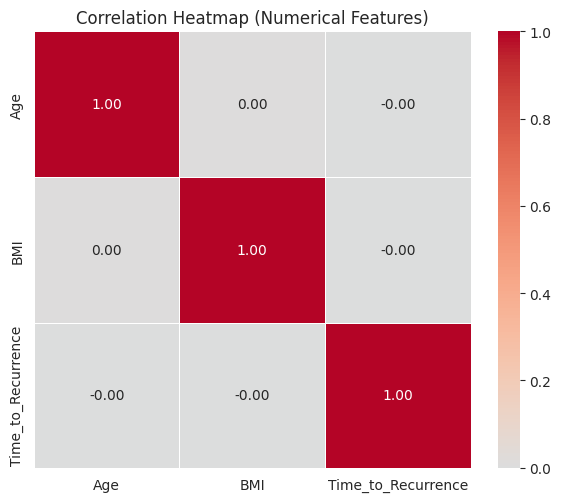

In [7]:
# Correlation heatmap (numerical features only)
plt.figure(figsize=(6, 5))
num_cols = df.select_dtypes(include=[np.number]).columns.drop(['Patient_ID'])
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, linewidths=0.5)
plt.title('Correlation Heatmap (Numerical Features)')
plt.tight_layout()
plt.show()

## Data Preprocessing
- Handle missing values
- Encode categorical variables
- Normalize numerical features

In [8]:
# Drop unnecessary columns (e.g., Patient ID if present)
df_model = df.drop(columns=['Patient_ID'])

# Drop outcome-adjacent columns that would leak information about survival status.
# 'Recurrence' and 'Time_to_Recurrence' describe what happened AFTER the survival outcome
# is known (or are only meaningful in light of it), so including them would make the task
# artificially easy and not reflect a realistic prediction-at-diagnosis scenario.
df_model = df_model.drop(columns=['Recurrence', 'Time_to_Recurrence'])

# Encode categorical variables
df_model['Survival_Status'] = df_model['Survival_Status'].map({'Survived': 1, 'Deceased': 0})

categorical_cols = df_model.select_dtypes(include='object').columns.tolist()
df_model = pd.get_dummies(df_model, columns=categorical_cols, drop_first=True)

# Define features and target variable
X = df_model.drop(columns=['Survival_Status'])  # Adjust target column name as needed
y = df_model['Survival_Status']

print('Feature columns:', X.columns.tolist())
print('\nTarget distribution:')
print(y.value_counts())

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'\nTraining set: {X_train.shape}, Test set: {X_test.shape}')

/tmp/ipykernel_728/2415297251.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_model.select_dtypes(include='object').columns.tolist()


Feature columns: ['Age', 'BMI', 'Gender_Male', 'Race_Black', 'Race_Hispanic', 'Race_Other', 'Race_White', 'Region_Asia Pacific', 'Region_Europe', 'Region_Latin America', 'Region_North America', 'Urban_or_Rural_Urban', 'Socioeconomic_Status_Low', 'Socioeconomic_Status_Middle', 'Family_History_Yes', 'Previous_Cancer_History_Yes', 'Stage_at_Diagnosis_II', 'Stage_at_Diagnosis_III', 'Stage_at_Diagnosis_IV', 'Tumor_Aggressiveness_Low', 'Tumor_Aggressiveness_Medium', 'Colonoscopy_Access_Yes', 'Screening_Regularity_Never', 'Screening_Regularity_Regular', 'Diet_Type_Traditional', 'Diet_Type_Western', 'Physical_Activity_Level_Low', 'Physical_Activity_Level_Medium', 'Smoking_Status_Former', 'Smoking_Status_Never', 'Alcohol_Consumption_Low', 'Alcohol_Consumption_Medium', 'Red_Meat_Consumption_Low', 'Red_Meat_Consumption_Medium', 'Fiber_Consumption_Low', 'Fiber_Consumption_Medium', 'Insurance_Coverage_Yes', 'Time_to_Diagnosis_Timely', 'Treatment_Access_Limited', 'Chemotherapy_Received_Yes', 'Radiot


Training set: (71956, 43), Test set: (17989, 43)


## Model Training
Train a **Logistic Regression** model to predict patient survival.

In [9]:
# Train a Logistic Regression model
model = LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42)
model.fit(X_train_scaled, y_train)

# Predictions
y_pred = model.predict(X_test_scaled)
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

# Model evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_pred_proba))
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=['Deceased', 'Survived']))

Accuracy: 0.505975874145311
ROC AUC: 0.5072364835138558

Classification Report:
               precision    recall  f1-score   support

    Deceased       0.25      0.50      0.34      4521
    Survived       0.75      0.51      0.61     13468

    accuracy                           0.51     17989
   macro avg       0.50      0.50      0.47     17989
weighted avg       0.63      0.51      0.54     17989



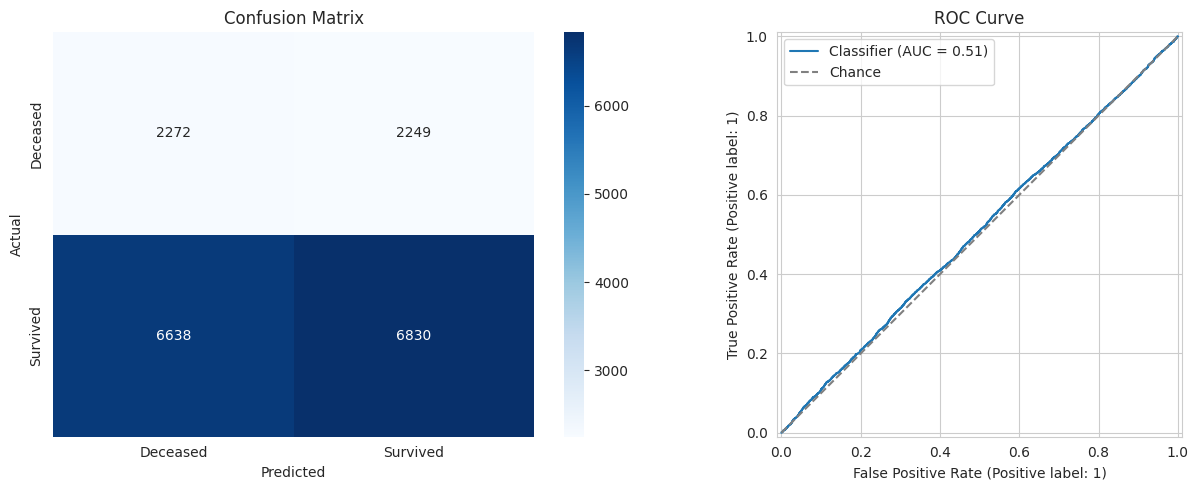

In [10]:
# Confusion matrix and ROC curve
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Deceased', 'Survived'], yticklabels=['Deceased', 'Survived'], ax=axes[0])
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
axes[0].set_title('Confusion Matrix')

RocCurveDisplay.from_predictions(y_test, y_pred_proba, ax=axes[1])
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Chance')
axes[1].set_title('ROC Curve')
axes[1].legend()

plt.tight_layout()
plt.show()

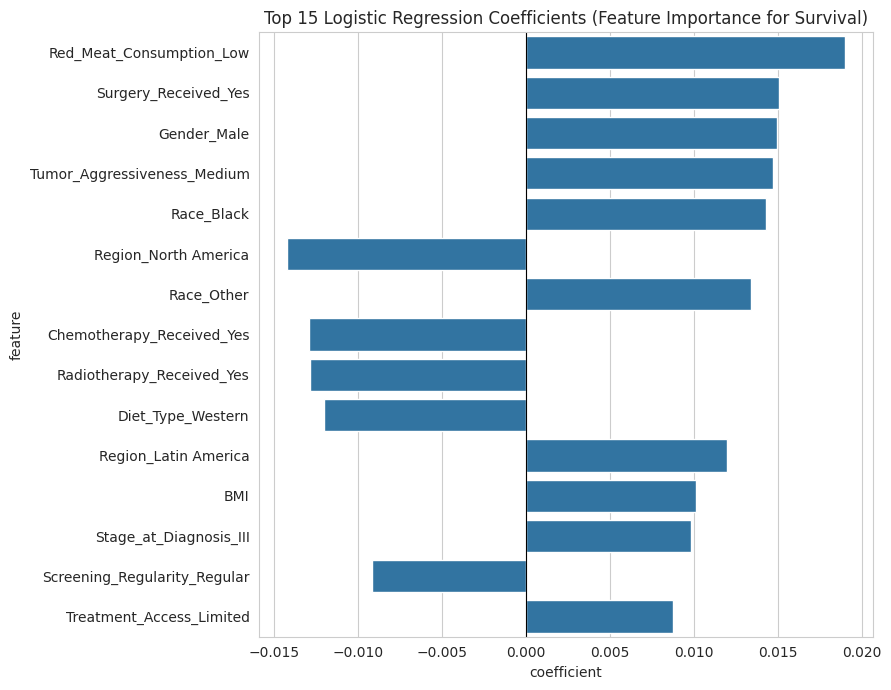

,feature,coefficient
32,Red_Meat_Consumption_Low,0.019000
41,Surgery_Received_Yes,0.015070
2,Gender_Male,0.014940
20,Tumor_Aggressiveness_Medium,0.014726
3,Race_Black,0.014299
10,Region_North America,-0.014221
5,Race_Other,0.013414
39,Chemotherapy_Received_Yes,-0.012892
40,Radiotherapy_Received_Yes,-0.012837
25,Diet_Type_Western,-0.012026


In [11]:
# Feature importance
coef_df = pd.DataFrame({
    'feature': X.columns,
    'coefficient': model.coef_[0]
}).sort_values('coefficient', key=abs, ascending=False).head(15)

plt.figure(figsize=(9, 7))
sns.barplot(data=coef_df, x='coefficient', y='feature')
plt.title('Top 15 Logistic Regression Coefficients (Feature Importance for Survival)')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

coef_df

## Conclusion
- **The model performs no better than chance (ROC AUC ≈ 0.51, accuracy ≈ 0.51).** This is not a modeling bug: a direct crosstab of `Stage_at_Diagnosis` and `Tumor_Aggressiveness` against `Survival_Status` shows the survival rate is ≈75% in *every* stage and every aggressiveness level, including Stage IV and 'High' aggressiveness. In real colorectal cancer data these are among the strongest known prognostic factors, so their absence here indicates the outcome column in this dataset is not generated from the other columns (i.e. it behaves like a synthetic/randomly-assigned label rather than real clinical data).
- Because of this, the feature-importance coefficients above should **not** be interpreted as real clinical risk factors — they mostly reflect noise, and none of them meaningfully separate the two classes.
- `Recurrence` and `Time_to_Recurrence` were still deliberately excluded from the model as they are outcome-adjacent and would leak information not available at the time of a realistic prediction, regardless of this finding.
- Before drawing conclusions from this dataset, it would be worth checking its source/documentation for how `Survival_Status` was generated. If a genuine predictive signal is needed, a dataset where the outcome is actually derived from the clinical features (e.g. a real cancer registry) would be required — no amount of additional modeling (tree-based methods, tuning, etc.) can recover a relationship that isn't present in the data.